# 大模型微调 05：LangChain 与物流行业 RAG

本篇整理所有 `05` 开头资料：LangChain 笔记、物流行业 RAG 笔记、两份课件、`langchain_apply` 代码、物流知识库数据与 FAISS 索引。内容先介绍 LangChain 的六类组件，再通过物流信息咨询项目串起“文档加载 → 切分 → 向量化 → 相似检索 → 生成回答 → Web 对话”的完整 RAG 流程。


## 一、什么是 LangChain

LangChain 由 Harrison Chase 于 2022 年创建，是围绕大语言模型建立的应用开发框架。它不负责训练或开发 LLM，而是为不同模型提供通用接口，把模型、Prompt、记忆、索引、链和代理等组件连接起来，降低复杂 LLM 应用的开发难度。

LangChain 同时提供 Python 和 Node.js 实现。课程资料使用 Python，并配合本地 Ollama 模型。


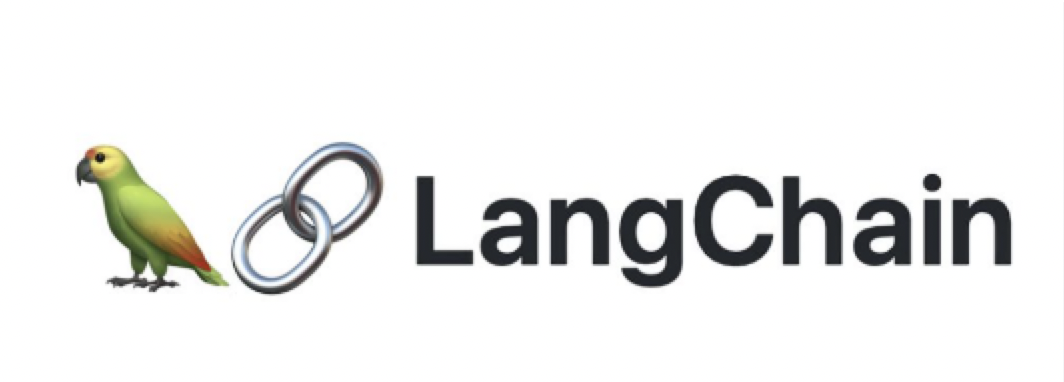

## 二、LangChain 的六类核心组件

| 组件 | 作用 |
| --- | --- |
| Models | 统一封装 LLM、Chat Model 和 Embeddings |
| Prompts | 管理、优化、序列化提示模板 |
| Memory | 保存模型交互中的上下文状态 |
| Indexes | 加载、切分和结构化文档，支持检索 |
| Chains | 把多个组件按顺序连接成应用流程 |
| Agents | 让模型选择工具、执行动作并观察结果 |

安装基础依赖：

```bash
pip install langchain
pip install ollama
pip install langchain_community
```


## 三、Models：三类模型接口

### 3.1 LLM

LLM 接收字符串，返回字符串，适合直接完成文本生成：

```python
from langchain_community.llms import Ollama

model = Ollama(model="qwen2.5:7b")
result = model.invoke("请给我讲个鬼故事")
print(result)
```

### 3.2 Chat Models

Chat Model 接收有角色的消息列表，常见消息类型是：

- `SystemMessage`：设定角色、背景和行为约束；
- `HumanMessage`：用户输入；
- `AIMessage`：模型历史回复。

```python
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langchain_community.chat_models import ChatOllama

model = ChatOllama(model="qwen2.5:7b")
messages = [
    SystemMessage(content="现在你是一个著名的诗人"),
    HumanMessage(content="给我写一首唐诗"),
]
res = model.invoke(messages)
print(res.content)
```


### 3.3 Embeddings Models

嵌入模型将字符串转换为浮点数向量，用于相似度检索和向量数据库：

```python
from langchain_community.embeddings import OllamaEmbeddings

model = OllamaEmbeddings(model="mxbai-embed-large", temperature=0)
query_vector = model.embed_query("这是第一个测试文档")
document_vectors = model.embed_documents([
    "这是第一个测试文档",
    "这是第二个测试文档",
])
```

LLM 负责生成，Chat Model 负责多轮消息，Embeddings 负责把文本映射到向量空间，三者在 RAG 中分别承担不同职责。


## 四、Prompts：从模板到 few-shot

Prompt 是传给模型的提示信息。LangChain 的 `PromptTemplate` 可以把稳定的任务描述和变化的输入分开。

### 4.1 Zero-shot 模板

```python
from langchain import PromptTemplate

template = "我的邻居姓{lastname}，他生了个儿子，给他儿子起个名字"
prompt = PromptTemplate(
    input_variables=["lastname"],
    template=template,
)
prompt_text = prompt.format(lastname="王")
```

### 4.2 Few-shot 模板

`FewShotPromptTemplate` 把多个示例统一插入 Prompt：

```python
from langchain import PromptTemplate, FewShotPromptTemplate

examples = [
    {"word": "开心", "antonym": "难过"},
    {"word": "高", "antonym": "矮"},
]
example_prompt = PromptTemplate(
    input_variables=["word", "antonym"],
    template="单词: {word}
反义词: {antonym}
",
)
few_shot_prompt = FewShotPromptTemplate(
    examples=examples,
    example_prompt=example_prompt,
    prefix="给出每个单词的反义词",
    suffix="单词: {input}
反义词:",
    input_variables=["input"],
)
print(few_shot_prompt.format(input="粗"))
```


## 五、Chains：把多个调用串起来

Chain 表示将 Prompt、模型或其他组件组合成一个可复用流程。最简单的例子是把 PromptTemplate 和 LLM 连接起来：

```python
from langchain import PromptTemplate
from langchain_community.llms import Ollama
from langchain.chains import LLMChain

prompt = PromptTemplate(
    input_variables=["lastname"],
    template="我的邻居姓{lastname}，他生了个儿子，给他起一个名字",
)
llm = Ollama(model="qwen2.5:7b")
chain = LLMChain(llm=llm, prompt=prompt)
print(chain.run("王"))
```

`SimpleSequentialChain` 可以把第一个链的输出直接交给第二个链，例如先生成大名，再根据大名生成小名。代码目录中对应 `Chain_module/zero-shot-langchain.py` 和 `Simple_Sequential_Chain.py`。


## 六、Agents：让模型选择工具

Agent 的核心是让模型根据用户需求选择下一步动作，调用搜索、计算器、数据库等工具，再根据观察结果继续执行。相关角色包括：

- Agent：制定计划并决定动作；
- Tool：完成计算或访问外部服务；
- Toolkit：一组已经集成好的工具；
- AgentExecutor：循环运行 Agent 和工具，直到达到停止条件。

示例使用 `llm-math` 解决方程：

```python
from langchain.agents import initialize_agent, AgentType
from langchain_community.llms import Ollama
from langchain_community.agent_toolkits.load_tools import load_tools

llm = Ollama(model="qwen2.5:7b")
tools = load_tools(["llm-math"], llm=llm)
agent = initialize_agent(
    tools, llm,
    agent=AgentType.ZERO_SHOT_REACT_DESCRIPTION,
    verbose=True,
)
print(agent.run("解以下方程：3x + 4(x + 2) - 84 = y；其中 x 为 3"))
```

使用 `serpapi` 等联网工具还需要额外申请 token；本地示例只使用数学工具。


## 七、Memory：保存对话上下文

LLM 本身不会自动记住上一次对话，应用需要把历史消息再次传给模型。LangChain 将记忆分为单会话的短期记忆和跨会话的长期记忆，课程重点使用 `ChatMessageHistory` 和 `ConversationChain`。

```python
from langchain.memory import ChatMessageHistory

history = ChatMessageHistory()
history.add_user_message("在吗？")
history.add_ai_message("有什么事?")
print(history.messages)
```

需要持久化时，可以使用 `messages_to_dict()` 将消息序列化，再用 `messages_from_dict()` 恢复。`ConversationChain` 则把历史自动带入连续对话。


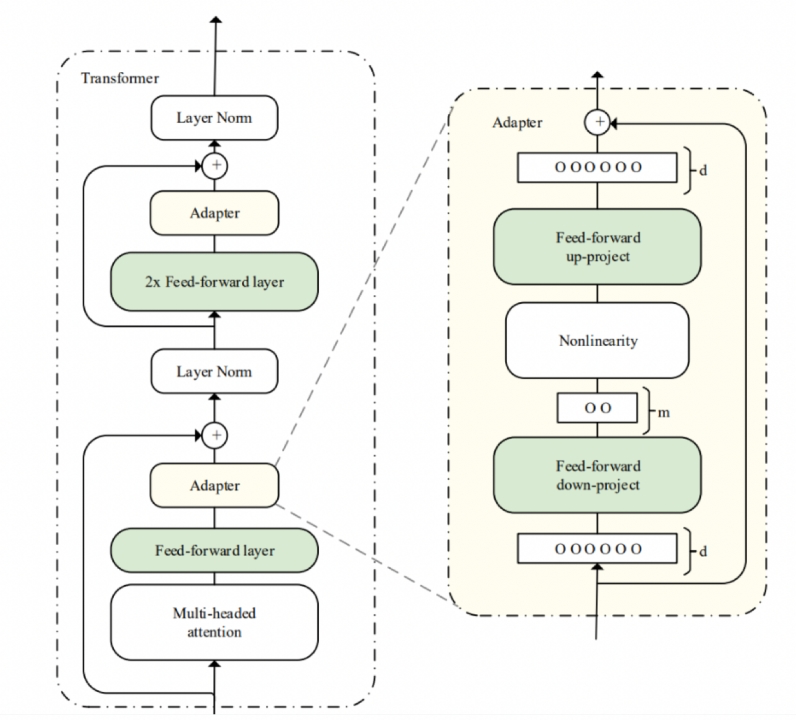

## 八、Indexes：让模型能够处理文档

Indexes 负责文档加载和检索，主要包括：

1. **Document Loaders**：加载 TXT、PDF、Markdown、CSV、PPT、图片等；
2. **Text Splitters**：将长文本切成适合模型上下文长度的片段；
3. **VectorStores**：保存文本向量并支持相似度搜索；
4. **Retrievers**：根据查询返回相关 Document。

文本切分需要保持语义完整，不能简单地把一个函数或一句话从中间截断。`CharacterTextSplitter` 适合基础示例，实际长文档常使用递归切分器、Markdown 切分器或按 token 切分器。


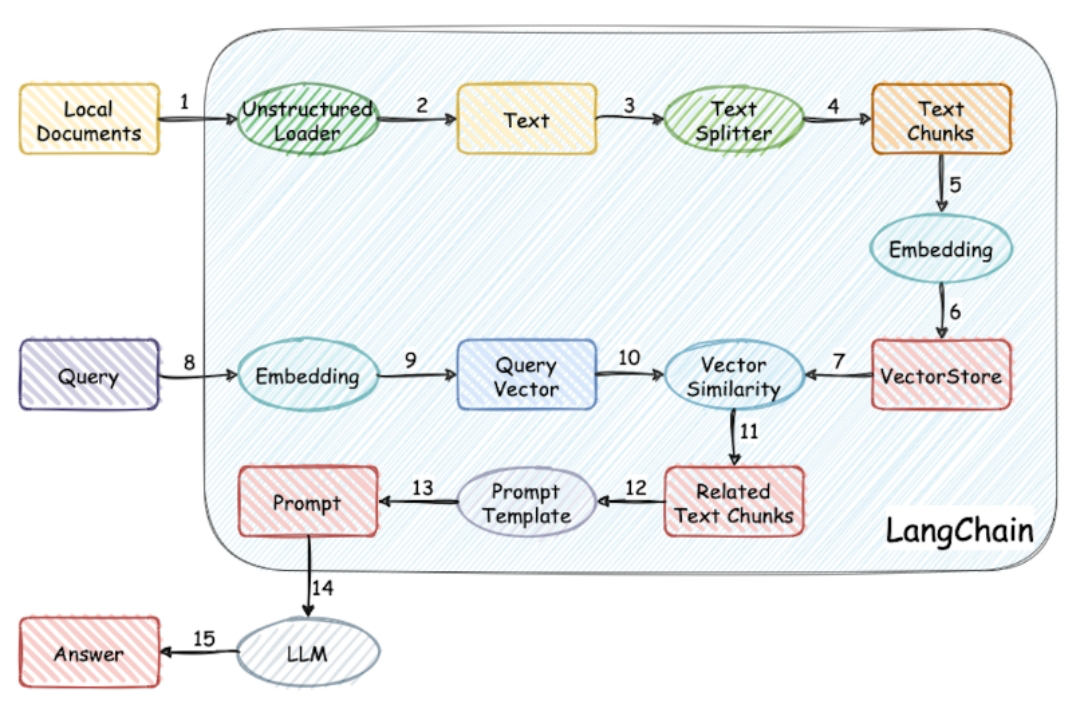

### 8.1 文档加载和切分

```python
from langchain_community.document_loaders import TextLoader
from langchain.text_splitter import CharacterTextSplitter

loader = TextLoader("./pku.txt", encoding="utf8")
documents = loader.load()
text_splitter = CharacterTextSplitter(
    separator=" ",
    chunk_size=100,
    chunk_overlap=0,
)
texts = text_splitter.split_documents(documents)
```

`chunk_overlap` 用来保留相邻片段之间的少量重叠，避免关键信息正好位于边界时被切断。


### 8.2 VectorStore 与 Retriever

LangChain 可以使用 Chroma、FAISS、Milvus、Redis、Pinecone 等向量数据库。课程示例使用 Ollama 的 `mxbai-embed-large` 生成向量，再用 FAISS 或 Chroma 做相似搜索。

```python
from langchain_community.embeddings import OllamaEmbeddings
from langchain_community.vectorstores import FAISS

embeddings = OllamaEmbeddings(model="mxbai-embed-large")
db = FAISS.from_documents(texts, embeddings)
retriever = db.as_retriever(search_kwargs={"k": 1})
docs = retriever.get_relevant_documents("北京大学什么时候成立的")
print(docs)
```

代码目录中的 `Indexes_module` 还包含 TextLoader、CharacterTextSplitter、Chroma 和 FAISS 的对照示例。


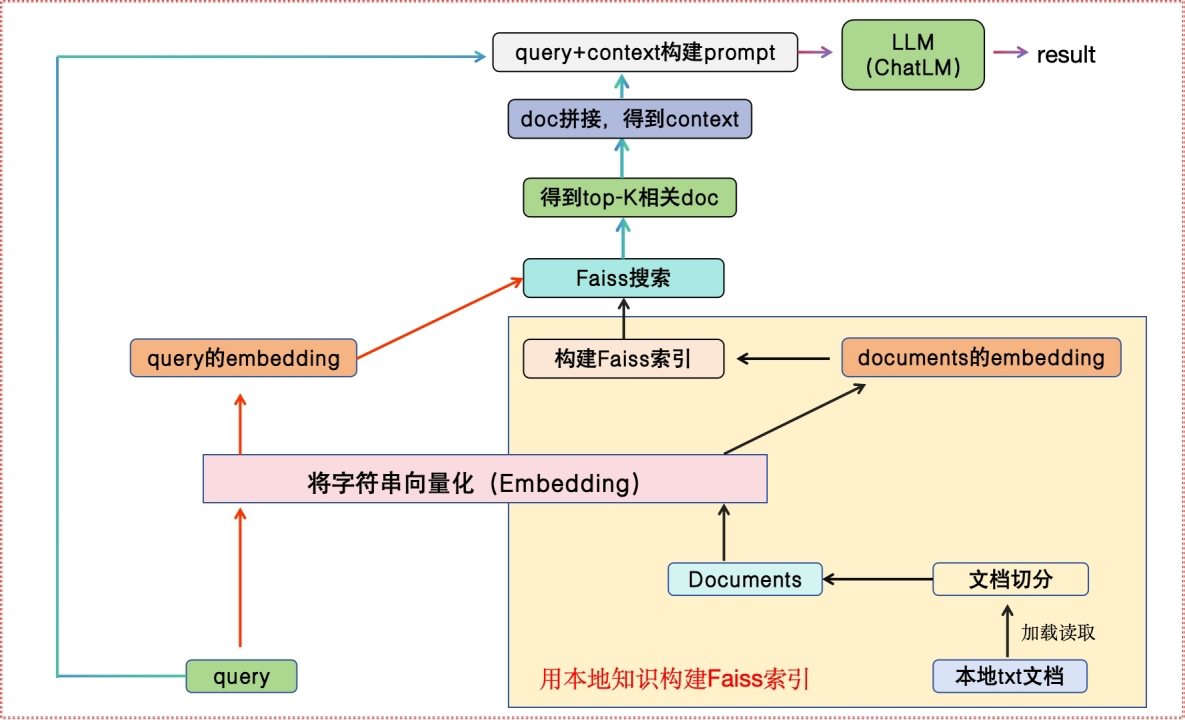

## 九、物流行业 RAG 项目

### 9.1 为什么需要 RAG

通用 LLM 主要基于历史训练数据，无法自动获得最新知识和企业私有数据。企业通常有两条路线：

- 使用私有数据对开源模型进行微调；
- 把私有文档接入向量数据库，检索相关片段后交给 LLM 生成回答，即 RAG。

本项目以物流信息 PDF 为知识源，支持本地、离线和私有化部署，也可以将物流行业替换为其他行业。


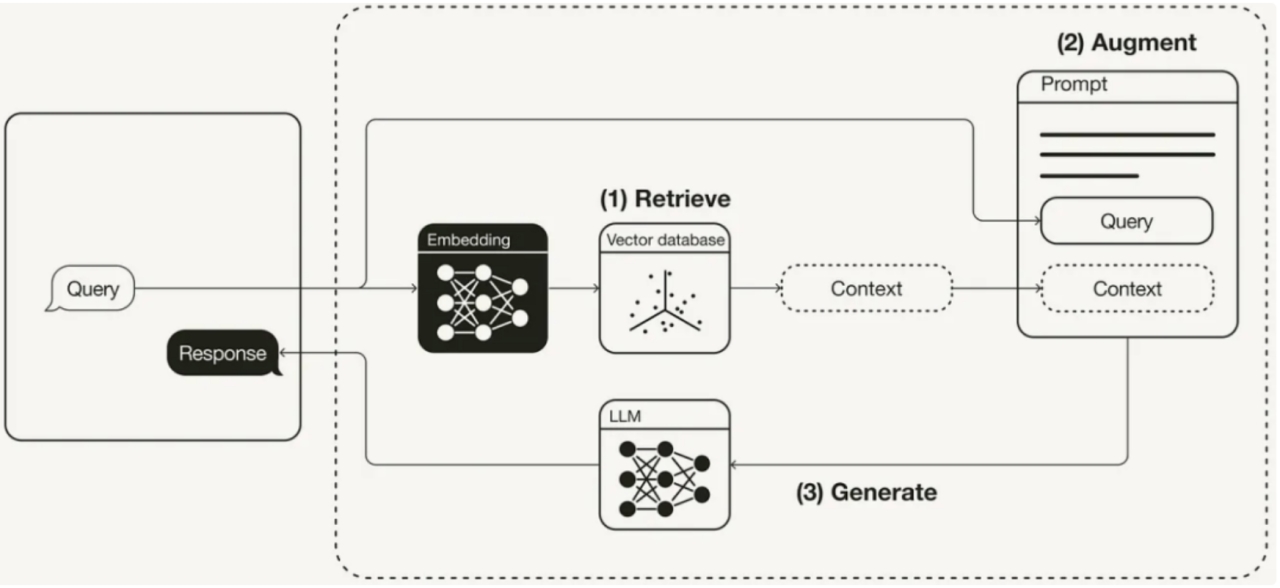

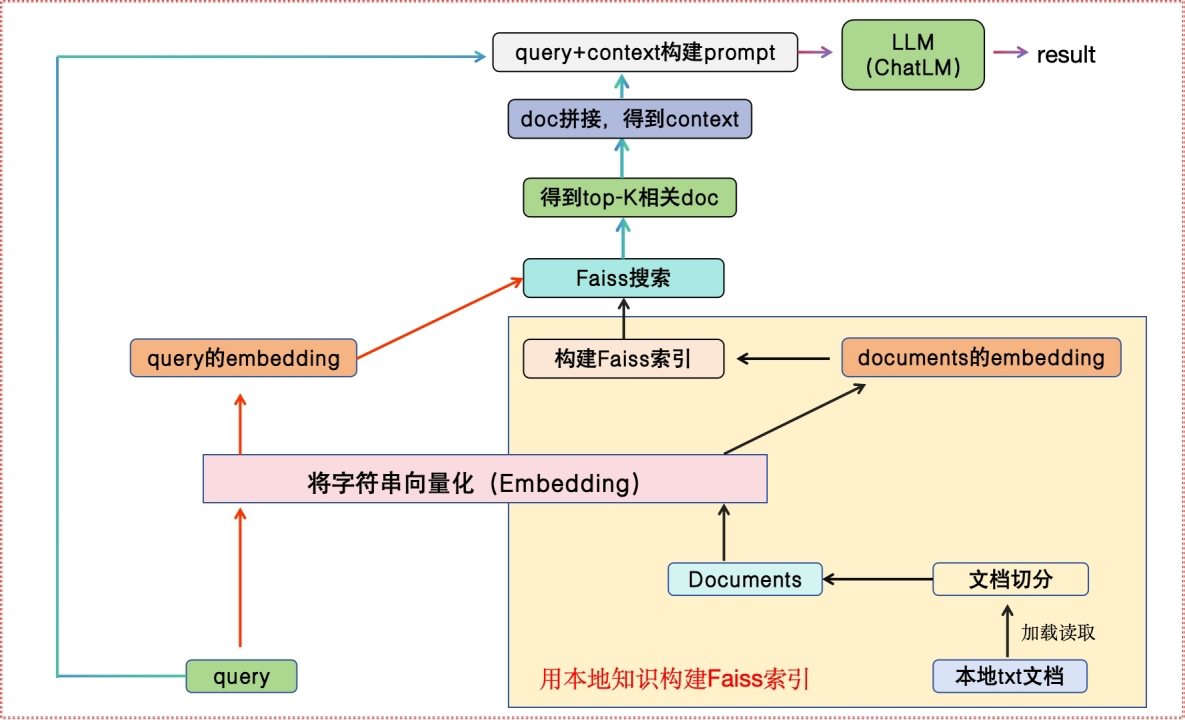

### 9.2 RAG 的完整流程

```text
加载 PDF → 抽取文本 → 文本切分 → Embedding 向量化 → 保存向量库
                                             ↓
用户问题 → 问题向量化 → 相似度检索 top_k 文档 → 组成上下文 Prompt → LLM 生成答案
```

检索出的文本是模型回答的依据，Prompt 应明确要求模型只基于已知内容回答，不要编造。


### 9.3 环境准备

项目要求 Python 3.8–3.11，并安装：

```bash
pip install faiss-cpu
pip install langchain
pip install ollama
```

本地运行还需要通过 Ollama 下载聊天模型和嵌入模型，例如 `qwen2.5:7b` 与 `mxbai-embed-large`。模型目录和服务地址应与本机 Ollama 配置一致。


### 9.4 构建本地 FAISS 知识库

下面是 `05-代码/langchain_apply/Knowledge_QA/local_db.py` 的完整代码：


```python
from langchain_community.document_loaders import PyMuPDFLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter
from langchain_community.embeddings import OllamaEmbeddings
from langchain_community.vectorstores import FAISS # 向量数据库


def get_vector():
    # 第一步：加载文档
    loader = PyMuPDFLoader("物流信息.pdf")
    # 将文本转成 Document 对象
    data = loader.load()
    print(f'data-->{data}')
    print(f'len(data):{len(data)}')

    # # 第二步：切分文本
    text_splitter = RecursiveCharacterTextSplitter(chunk_size=50, chunk_overlap=20)
    # # 切割加载的 document
    split_docs = text_splitter.split_documents(data)
    print("split_docs size:", len(split_docs))
    print(split_docs)
    #
    # # 第三步：初始化 hugginFace 的 embeddings 对象
    embeddings = OllamaEmbeddings(model="mxbai-embed-large")
    #
    #
    # # 第四步：将 document通过embeddings对象计算得到向量信息并永久存入FAISS向量数据库，用于后续匹配查询
    db = FAISS.from_documents(split_docs, embeddings)
    db.save_local("./faiss/wuliu")

if __name__ == '__main__':
    result = get_vector()
```

这一步完成四件事：

1. 用 `PyMuPDFLoader` 读取 `物流信息.pdf`；
2. 用 `RecursiveCharacterTextSplitter` 按 `chunk_size=50`、`chunk_overlap=20` 切分；
3. 用 `OllamaEmbeddings` 将文本片段转换为向量；
4. 用 `FAISS.from_documents()` 创建向量库并保存到 `./faiss/wuliu`。


### 9.5 基于检索结果生成回答

下面是 `local_qa.py` 的完整代码：


```python
# coding:utf-8
# 导入必备的工具包
import time
from local_db import *
from langchain import PromptTemplate
from langchain_community.llms import Ollama


# 加载FAISS向量库
embeddings = OllamaEmbeddings(model="mxbai-embed-large", temperature=0)
db = FAISS.load_local("faiss/wuliu", embeddings, allow_dangerous_deserialization=True)
# db = FAISS.load_local("faiss/wuliu", embeddings)

start_time = time.time()


def get_related_content(related_docs):
    # print(f'related_docs--》{related_docs}')
    related_content = []
    for doc in related_docs:
        # print(f'doc.page_content--》{doc.page_content}')
        related_content.append(doc.page_content.replace("\n\n", "\n"))
    # print(f'related_content列表状态--》{related_content}')

    return "\n".join(related_content)


def define_prompt():
    question = '我的快递出发地是哪？预计几天的时间到达？'
    docs = db.similarity_search(question, k=2)

    related_content = get_related_content(docs)
    # print('*' * 80)
    # print(f'related_content字符串状态-->{related_content}')
    # print('*'*80)
    PROMPT_TEMPLATE = """
        基于以下已知信息，简洁和专业的来回答用户的问题。不允许在答案中添加编造成分。
        已知内容:
        {context}
        问题:
        {question}"""

    prompt = PromptTemplate(
        input_variables=["context", "question"],
        template=PROMPT_TEMPLATE,)

    my_pmt = prompt.format(context=related_content,
                           question=question)

    return my_pmt


def qa():
    model = Ollama(model="qwen2.5:7b")
    # print(f'model-->{model}')
    my_pmt = define_prompt()
    print(f'my_pmt--》{my_pmt}')
    # result = model.invoke(my_pmt)
    # return result



if __name__ == '__main__':
    result = qa()
    print(result)
    end_time = time.time()
    print(end_time-start_time)
```

回答 Prompt 的关键约束是：

```text
基于以下已知信息，简洁和专业地回答用户的问题，不允许在答案中添加编造成分。
```

查询时使用 `similarity_search(question, k=2)` 找到两个相关片段，再将它们拼接为 `{context}`，和 `{question}` 一起交给 Qwen2.5。


### 9.6 Streamlit Web 界面

下面是 `web_qa.py` 的核心实现：


```python
from local_qa import *
# ConversationalRetrievalChain作用：自动保存历史对话信息
from langchain.chains import ConversationalRetrievalChain
import streamlit as st

# 设置标题
st.set_page_config(page_title="物流行业信息咨询系统")
st.title("物流行业信息咨询RAG系统")

# 初始化全局变量
chat_history = []


# 定义检索链函数
def new_retrival():
    """
    创建基于 ConversationalRetrievalChain 的问答链。
    """
    chain = ConversationalRetrievalChain.from_llm(
        llm=Ollama(model="qwen2.5:7b"),  # 使用本地大模型
        retriever=db.as_retriever()        # 基于本地数据库的检索器
    )
    return chain

# 主逻辑
def main():
    """
    Streamlit 主页面的交互逻辑。
    """
    # print(f'st.session_state-->{st.session_state}')
    # 初始化会话状态
    if "messages" not in st.session_state:
        st.session_state.messages = []  # 用于保存聊天记录
    # print(f'st.session_state-->{st.session_state}')
    # 展示历史聊天记录
    for message in st.session_state.messages:
        # print(f'message["role"]-->{message["role"]}')
        with st.chat_message(message["role"]):
            st.markdown(message["content"])  # 显示消息内容

    # 接受用户输入
    # prompt = st.chat_input("请输入你的问题:")
    if prompt := st.chat_input("请输入你的问题:"):
        # 保存用户消息到会话状态
        print(f'prompt--》{prompt}')
        st.session_state.messages.append({"role": "user", "content": prompt})

        # 显示用户输入
        with st.chat_message("user"):
            st.markdown(prompt)

        # 调用模型获取回答
        with st.chat_message("assistant"):
            # 占位符用于显示逐字生成的回答
            message_placeholder = st.empty()
            full_response = ""

            # 调用检索链获取答案
            chain = new_retrival()
            result = chain.invoke({"question": prompt, "chat_history": chat_history})
            print(f'result--->{result}')
            chat_history.append((prompt, result["answer"]))  # 更新聊天历史
            assistant_response = result["answer"]
            message_placeholder.markdown(assistant_response)

            # 保存回答到会话状态
            st.session_state.messages.append({"role": "assistant", "content": assistant_response})

# 运行主逻辑
if __name__ == "__main__":
    main()

```

`ConversationalRetrievalChain` 把 LLM、Retriever 和聊天历史连接起来；Streamlit 用 `st.session_state.messages` 保存页面历史消息，用 `st.chat_input()` 接收用户问题，用 `st.chat_message()` 展示对话。


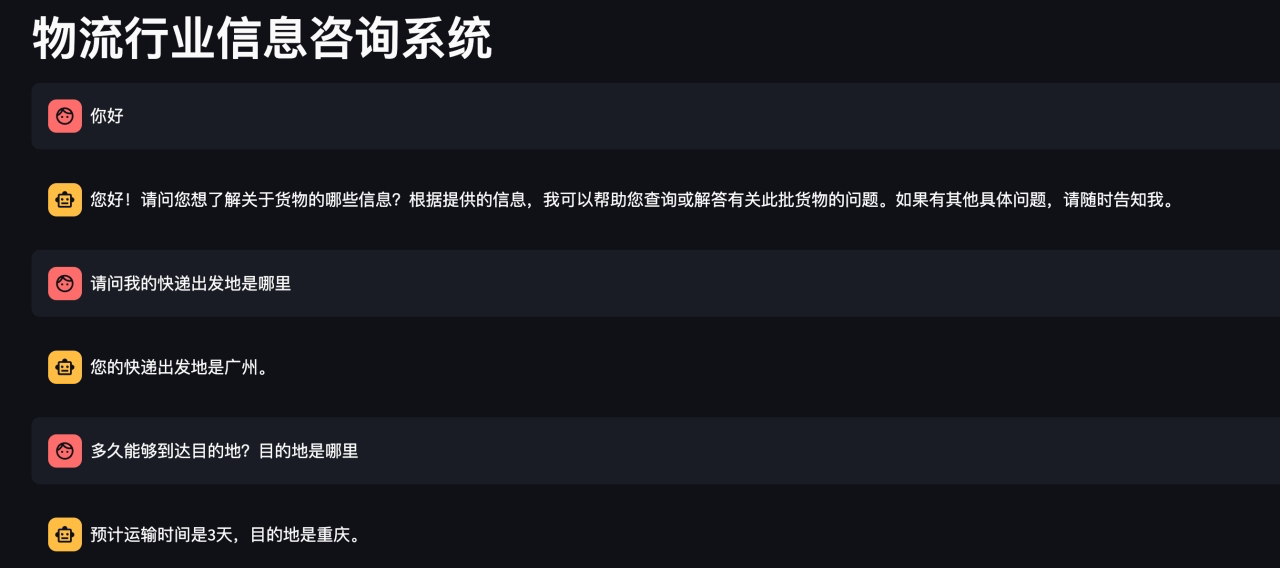

## 十、已下载代码目录的作用

| 目录 | 主要示例 |
| --- | --- |
| `Models_module` | Ollama LLM、ChatOllama、Embedding、Prompt |
| `Prompts_module` | zero-shot 与 few-shot PromptTemplate |
| `Chain_module` | LLMChain、SimpleSequentialChain |
| `Agents_module` | llm-math 工具和 AgentExecutor |
| `Memory_module` | ChatMessageHistory、消息序列化、ConversationChain |
| `Indexes_module` | 文档加载、切分、Chroma、FAISS、Retriever |
| `Knowledge_QA` | 物流 PDF、向量库构建、本地问答、Web 问答 |
| `langchain_glm` | 将本地 ChatGLM 包装成 LangChain LLM 接口 |

`05-附属资料` 中的物流 PDF、衣服属性、北京大学文本和 FAISS 索引，分别对应文档加载、向量检索和物流问答示例。


## 十一、排查要点

- `ollama` 服务是否启动，模型名称是否和代码一致？
- `mxbai-embed-large` 生成的向量维度和已保存 FAISS 索引是否一致？
- 重建向量库时，`chunk_size`、`chunk_overlap` 和嵌入模型是否保持一致？
- 使用 `FAISS.load_local()` 时，索引路径是否正确；只对可信本地索引使用 `allow_dangerous_deserialization=True`？
- 检索结果为空时，先打印 `docs` 和 `related_content`，确认加载、切分、嵌入和相似度查询每一步都有结果。
- Web 应用中要保存 `chat_history` 和 `st.session_state.messages`，否则刷新或多轮对话时会丢失上下文。


## 十二、本章总结

- LangChain 用统一接口连接模型、Prompt、Memory、Indexes、Chains 和 Agents。
- LLM、Chat Model 和 Embeddings 的输入输出不同，应用时要根据职责选择。
- RAG 的关键链路是文档切分、向量化、相似检索和基于上下文生成，检索结果决定回答依据。
- FAISS 负责本地向量索引，Ollama 提供聊天模型和嵌入模型，Streamlit 提供可交互页面。
- 实际项目中要验证模型、索引、切分参数和 Prompt 的一致性，并明确禁止模型编造知识。
